# Parameter importance of a sweep

A W&B-style "parameter importance" chart for one sweep: one row per swept parameter, with a
random-forest importance bar and a signed Kendall $\tau$ bar, both against **best validation
loss**, the metric the sweeps minimise (W&B's panel defaults to `Best/Val_acc`, and isn't
available through its API). It replaced the per-parameter scatter figure
(`param_correlation_*`, from [suggest_sweep.ipynb](./suggest_sweep.ipynb)) in thesis §4.5 on
2026-10-30.

- **Importance**: a random-forest regressor's impurity importance (as W&B uses), averaged over
  forests fitted to bootstrap resamples of the trials, with a 5th-95th percentile interval. With
  20 trials one forest's importances are unstable, so the interval is the point of the chart.
  Impurity importance under-rates parameters with few distinct values (here the two-valued
  `warmup_epochs`), so out-of-bag permutation importance is shown as a check.
- **Correlation**: Kendall $\tau$ with best val loss on all trials, as in the scatter figure;
  negative means higher values went with lower loss. It ignores the other parameters, which the
  Bayesian search did not sample independently.

Helpers: [helpers.py](./helpers.py) (`param_importance`, `oob_permutation_importance`); the
chart is `visualise2.plot_param_importance`.

In [1]:
from pathlib import Path
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.que.core import CompExpInfo
from src.results import get_asset_path, get_out_stub, get_stash_path, load_runs
from src.results.sweeping.helpers import (
    load_sweep_key_map,
    load_sweep_run_jsons,
    load_tuned_params,
    oob_permutation_importance,
    param_importance,
    sweep_frame,
)
from src.run_types import CONFIGS_PATH, RUNS_PATH
from src.visualise2 import plot_param_importance, save_fig, set_thesis_style

set_thesis_style()

## Sweep

`sweep` picks one of `sweeps`. Sweep 1's trials ran under the v1 Que and are stashed by
[suggest_sweep.ipynb](./suggest_sweep.ipynb); sweep 2's ran under Que_v2, so they are read from
each trial's `run.json` (finished trials only).

In [2]:
class Sweep(NamedTuple):
    label: str  # in the figure title and file name
    model: str
    split: str  # the split name its stash/asset stub uses
    sweep_id: str
    config_dir: Path  # holds config.yaml and base.py


sweeps = {
    'sweep 1': Sweep(
        'MViTv2-S sweep 1', 'MViTv2_S_16x4_e', 'asl100_cutoff_9', '510lhysg',
        CONFIGS_PATH / 'sweeps' / 'MViTv2_S_16x4_e' / 'exp001',
    ),
    'sweep 2': Sweep(
        'MViTv2-S sweep 2', 'MViTv2_S_e', 'asl100', 'flx99idx',
        CONFIGS_PATH / 'sweeps' / 'MViTv2_S_e' / 'exp000',
    ),
}
sweep = sweeps['sweep 1']
project_name = 'sweeping'
n_classes = 100
diverged_loss = 0.9 * float(np.log(n_classes))  # as in suggest_sweep.ipynb
stub = get_out_stub(sweep.split, sweep.model, sweep.sweep_id)


def load_trials(s: Sweep) -> list[CompExpInfo]:
    """The sweep's finished trials: the v1 Que stash if there is one, else Que_v2's run.json files."""
    stash = get_stash_path(stub, base_name='runs')
    if stash.exists():
        return load_runs(stash)
    return load_sweep_run_jsons(RUNS_PATH / s.split / s.model / f'sweep_{s.sweep_id}')


tuned = load_tuned_params(sweep.config_dir / 'config.yaml')
trials = sweep_frame(load_trials(sweep), load_sweep_key_map(sweep.config_dir / 'base.py'), list(tuned))
diverged = trials['best_val_loss'] >= diverged_loss
print(f'{sweep.label}: {len(trials)} finished trials, {int(diverged.sum())} diverged (left out); '
      f'best val loss {trials["best_val_loss"].min():.3f}')
trials = trials.loc[~diverged].reset_index(drop=True)
trials[['run_id', 'best_val_loss', *tuned]]

MViTv2-S sweep 1: 20 finished trials, 0 diverged (left out); best val loss 0.570


,run_id,best_val_loss,backbone_init_lr,classifier_init_lr,backbone_weight_decay,classifier_weight_decay,drop_p,tmax,warmup_epochs,magnitude
0,fif03v0w,0.628240,0.000317,0.000030,0.076804,0.000063,0.394276,20,5,12
1,e0dgobm9,0.734514,0.000447,0.000013,0.020586,0.000049,0.129201,10,5,14
2,spptxw8q,0.643185,0.000371,0.000504,0.029422,0.007163,0.135740,28,5,15
3,7fa8utdj,0.589083,0.000402,0.000059,0.031072,0.001312,0.174171,17,5,12
4,t4wkave6,0.656426,0.000562,0.002981,0.095183,0.000045,0.185039,22,5,11
5,4b3dca0l,0.585436,0.000547,0.000104,0.037338,0.000122,0.184852,20,5,13
6,s0tura95,0.612265,0.000350,0.000081,0.069961,0.007517,0.309874,14,5,15
7,i1j2n0zd,0.593706,0.000397,0.000446,0.045176,0.001048,0.311160,25,5,15
8,q7tnljj8,0.610225,0.000507,0.000065,0.042991,0.000041,0.284948,27,5,15
9,8maut29t,0.611271,0.000413,0.000050,0.011679,0.000037,0.210310,18,5,13


## Importance and correlation

In [3]:
importance = param_importance(trials, tuned)
importance['oob_permutation'] = oob_permutation_importance(trials, tuned)
importance.round(3)

,importance,importance_low,importance_high,tau,tau_p,oob_permutation
param,,,,,,
drop_p,0.236,0.060,0.458,-0.011,0.974,0.028
backbone_init_lr,0.218,0.058,0.386,-0.411,0.011,0.117
backbone_weight_decay,0.171,0.032,0.332,-0.200,0.233,-0.005
classifier_init_lr,0.127,0.014,0.316,-0.021,0.924,0.007
magnitude,0.080,0.020,0.212,-0.318,0.060,-0.006
tmax,0.076,0.007,0.207,0.049,0.769,-0.003
warmup_epochs,0.054,0.005,0.178,0.526,0.006,0.017
classifier_weight_decay,0.038,0.004,0.116,0.053,0.773,0.014


## Chart

Saved as `param_importance_<label>_<stub>.pdf` under `results/outputs/sweeping/`.

Saved: /home/luke/Code/SLR/src/results/outputs/sweeping/param_importance_MViTv2-S_sweep_1_asl100_cutoff_9_MViTv2_S_16x4_e_510lhysg_.pdf


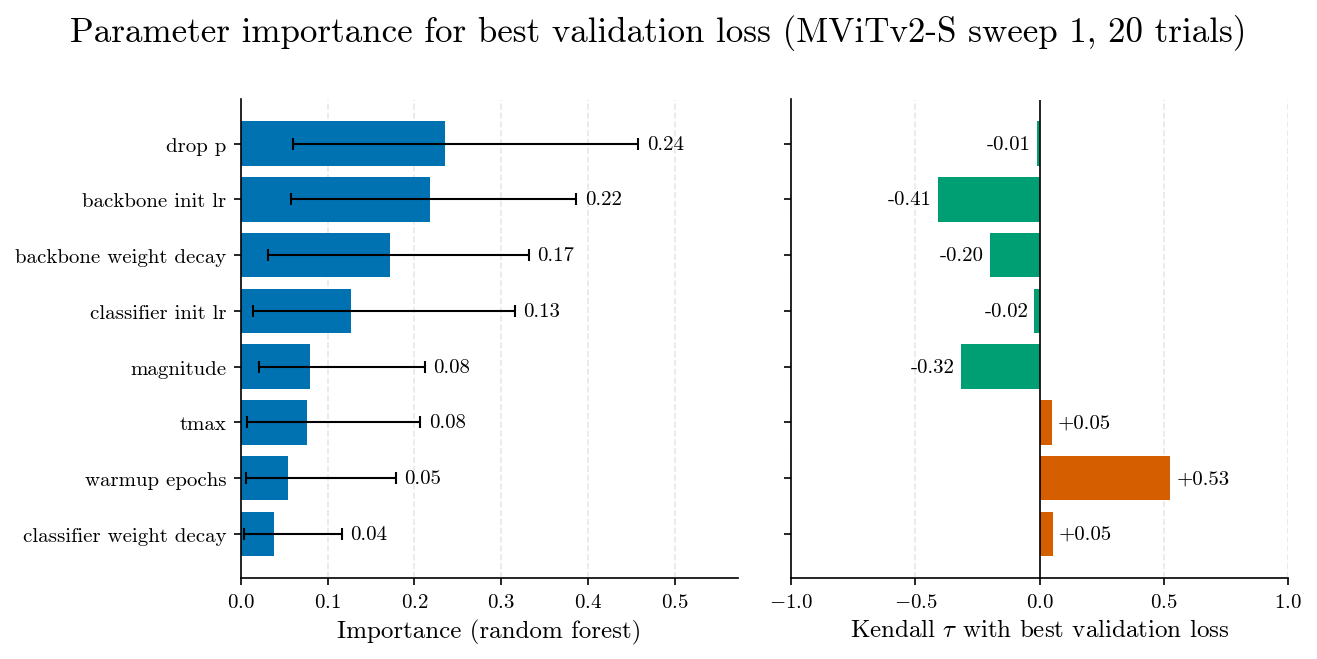

In [4]:
fig, axes = plot_param_importance(
    list(importance.index),
    importance['importance'],
    importance['tau'],
    importance_interval=(importance['importance_low'], importance['importance_high']),
    importance_label='Importance (random forest)',
    correlation_label=r'Kendall $\tau$ with best validation loss',
    title=f'Parameter importance for best validation loss ({sweep.label}, {len(trials)} trials)',
    figsize=(9, 4.5),
)
path = save_fig(fig, get_asset_path(f'param_importance_{sweep.label.replace(" ", "_")}', stub, project_name))
print(f'Saved: {path}')
plt.show()

## Stability: without the worst trial

The same table with the trial of highest best val loss left out. With ~20 trials, rankings that
change here rest on one trial and shouldn't be read into.

In [5]:
worst = int(np.argmax(trials['best_val_loss'].to_numpy()))
without_worst = trials.loc[trials.index != worst].reset_index(drop=True)
print(f'Left out: {trials.at[worst, "run_id"]} (best val loss {trials.at[worst, "best_val_loss"]:.3f})')
sensitivity = param_importance(without_worst, tuned)
sensitivity['oob_permutation'] = oob_permutation_importance(without_worst, tuned)
pd.DataFrame({
    'rank, all trials': importance['importance'].rank(ascending=False).astype(int),
    'rank, without worst': sensitivity['importance'].rank(ascending=False).astype(int),
    'importance, without worst': sensitivity['importance'],
    'oob permutation, without worst': sensitivity['oob_permutation'],
    'tau, without worst': sensitivity['tau'],
    'tau p, without worst': sensitivity['tau_p'],
}).loc[importance.index].round(3)

Left out: k8gfimyb (best val loss 0.956)


,"rank, all trials","rank, without worst","importance, without worst","oob permutation, without worst","tau, without worst","tau p, without worst"
param,,,,,,
drop_p,1,2,0.200,0.035,-0.111,0.534
backbone_init_lr,2,3,0.181,0.073,-0.345,0.041
backbone_weight_decay,3,5,0.077,-0.019,-0.111,0.534
classifier_init_lr,4,1,0.232,0.072,0.041,0.836
magnitude,5,6,0.068,0.007,-0.250,0.154
tmax,6,4,0.125,-0.014,0.127,0.459
warmup_epochs,7,8,0.054,0.016,0.464,0.019
classifier_weight_decay,8,7,0.064,0.011,0.064,0.730


## Sweep 1 (`510lhysg`, 20 trials, run 2026-10-30)

- **Only the backbone LR is robust.** It ranks 2nd-3rd by impurity importance, first by
  out-of-bag permutation importance (0.12 of the loss variance; tied with `classifier_init_lr` at
  0.07 without the worst trial), and is the only numeric parameter with a significant $\tau$
  ($-0.41$, p = 0.01; higher LR, lower loss), with or without the worst trial.
- **The rest of the impurity ranking is noise.** Every interval overlaps the others, and leaving
  out the worst trial (`best val loss 0.956`) moves `classifier_init_lr` from 4th to 1st, while
  `drop_p`'s 0.24 rests on that trial: its permutation importance is 0.03 and $\tau$ $-0.01$.
- **`warmup_epochs`** has the largest $\tau$ ($+0.53$, p = 0.006: the 5 trials with 8 warmup epochs
  did worse) but low impurity importance (0.05), partly the two-valued bias. Those 4 trials also
  had low backbone LRs (0.9e-4 to 2.4e-4) (the Bayesian search sampled them together), so the two effects can't be
  separated here.
- `magnitude` leans the same way as the backbone LR ($\tau$ $-0.32$, p = 0.06).